# Прогнозирование отмен бронирований отеля

## 1. Постановка задачи

### Бизнес-задача

Отели заранее планируют загрузку, персонал и доступность номеров. Отмена бронирования может привести к тому, что номер останется свободным и отель потеряет часть потенциального дохода. Задача — заранее оценить вероятность отмены, чтобы сотрудники могли учитывать риск при планировании загрузки и работе с гостями.

### Постановка ML-задачи

Будем решать задачу **бинарной классификации**: по данным, известным в момент оформления бронирования, оценить риск его последующей отмены. Целевая переменная — `is_canceled`: 1 означает отмену, 0 — отсутствие отмены. На данном этапе нас интересует способность модели различать будущие отмены и неотменённые бронирования, а не выбор конкретного действия отеля.

### Данные

Используем файл `hotel_bookings.csv`: 119 390 записей о бронированиях городского и курортного отелей. В нём есть целевая переменная и потенциальные признаки: срок до заезда, месяц, число гостей, стоимость номера, канал продаж и другие характеристики. Этого достаточно для построения и проверки базовой модели. При этом перед обучением нужно отобрать только признаки, действительно доступные в момент прогноза, и исключить информацию об итоговом статусе бронирования.

### Границы задачи

Последствия отмены зависят от того, когда она произойдёт: при ранней отмене у отеля обычно больше времени для повторной продажи номера, чем при отмене накануне заезда. Целевая переменная отражает только факт отмены, поэтому модель не отвечает на вопрос о её времени. Прогнозирование времени отмены, выбор стратегии овербукинга и оценка экономического эффекта выходят за рамки этой работы.

## 2. Метрика качества

Выбранная метрика — **ROC-AUC** (площадь под ROC-кривой). Она оценивает, насколько хорошо модель ранжирует отменённые бронирования выше неотменённых, и позволяет сравнивать модели без выбора конкретного порога классификации. Это соответствует нашей задаче: оценить способность модели различать два класса, пока правила принятия решений отелем не определены.

ROC-AUC около 0,5 соответствует случайному ранжированию, а 1 — идеальному разделению классов. Например, ROC-AUC = 0,8 означает, что в случайной паре отменённого и неотменённого бронирований модель примерно в 80% случаев поставит отменённое выше по риску (совпадающие оценки учитываются с весом 0,5).

При этом ROC-AUC не оценивает точность самих вероятностей: высокий результат не гарантирует, что среди бронирований с прогнозом 70% действительно отменятся 70%. Метрика также не измеряет прибыль от овербукинга или потери от отмен — для этого нужны отдельная постановка и дополнительные данные.

---

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/hotel_bookings.csv")

## Общая информация о данных

In [80]:
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [82]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [83]:
missing = df.isna().sum().sort_values(ascending=False)
print("Пропуски:")
print(missing[missing > 0])
print("\nПолностью совпадающие строки:", df.duplicated().sum())

Пропуски:
company     112593
agent        16340
country        488
children         4
dtype: int64

Полностью совпадающие строки: 31994


В таблице 119 390 строк и 32 столбца. Большинство пропусков находится в `company` и `agent`; отсутствие идентификатора может означать, что компания или агент не участвовали в бронировании, поэтому его не стоит автоматически заменять средним. Пропуски в `children` и `country` нужно обработать отдельно.

Есть полностью совпадающие строки, но уникального идентификатора бронирования нет: они могут быть как дублями, так и разными похожими заказами. Перед удалением нужно проверить происхождение данных.

### Текстовые обозначения неизвестных значений

`isna()` считает настоящие пропуски, но не строки `Unknown` или `Undefined`. Проверим такие обозначения отдельно, без изменения исходных данных. Это кандидаты на пропуски: само название ещё не доказывает, что значение отсутствует — в некоторых полях оно может обозначать отдельный вариант услуги.

In [84]:
# Текстовые обозначения, которые обычный isna() не учитывает
markers = ["unknown", "undefined", "null", "none", "na", "n/a", ""]
rows = []

for column in df.select_dtypes(include=["object", "string"]).columns:
    values = df[column].astype("string").str.strip().str.lower()
    mask = values.isin(markers)
    if mask.any():
        rows.append({
            "поле": column,
            "значения": ", ".join(df.loc[mask, column].unique()),
            "количество": int(mask.sum()),
            "доля строк, %": mask.mean() * 100,
            "обычные пропуски": int(df[column].isna().sum()),
            "отмены среди маркеров, %": df.loc[mask, "is_canceled"].mean() * 100,
            "отмены среди известных, %": df.loc[~mask & df[column].notna(), "is_canceled"].mean() * 100
        })

marker_stats = pd.DataFrame(rows)
marker_stats.round(2)

,поле,значения,количество,"доля строк, %",обычные пропуски,"отмены среди маркеров, %","отмены среди известных, %"
0,meal,Undefined,1169,0.98,0,24.47,37.17
1,market_segment,Undefined,2,0.00,0,100.00,37.04
2,distribution_channel,Undefined,5,0.00,0,80.00,37.04


В данных найдены значения `Undefined` в трёх полях; строк `Unknown` не обнаружено:

- `meal`: 1169 строк (около 0,98%). Доля отмен среди них — около 24,5%, среди остальных известных значений — 37,2%. Это достаточно заметная группа, поэтому удалять её не стоит. Значение может отражать особенность выбранного питания; перед объединением с другими категориями или переводом в пропуск нужно проверить описание поля.
- `market_segment`: 2 строки, обе с отменой.
- `distribution_channel`: 5 строк, из них 4 с отменой.

Для последних двух полей группы слишком малы, чтобы делать выводы о связи с отменой. Эти количества относятся к отдельным столбцам: одна строка может содержать несколько таких значений.

**Как обрабатывать:** числовым нулём заменять их не нужно — ноль станет отдельным значением, а не пропуском. Если описание данных подтверждает, что информация отсутствует, можно заменить маркер на `pd.NA` и затем учитывать его через `isna()`. Для категориальной модели допустимо оставить отдельную категорию неизвестного значения; главное — одинаково обрабатывать её при обучении и прогнозе. В этом EDA сохраняем исходные категории и учитываем их отдельно от настоящих пропусков. Различия в долях отмен здесь описательные и не доказывают причинности.

## Целевая переменная

<Axes: title={'center': 'Отмены бронирования'}>

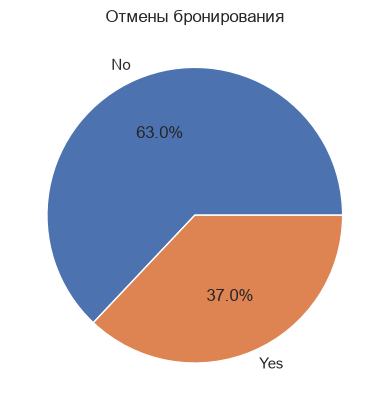

In [85]:
(
    df["is_canceled"].value_counts(normalize=True)
    .rename(index={0: "No", 1: "Yes"})
    .mul(100)
    .plot(
        kind="pie",
        title="Отмены бронирования",
        autopct="%1.1f%%",
    )
)

Отменено около 37% бронирований. Классы несбалансированы, хотя отмен достаточно много; одна только accuracy может скрыть низкое качество обнаружения отмен. Выбранная ROC-AUC оценивает ранжирование бронирований по риску отмены; ориентир случайного ранжирования — 0,5.

## Категориальные признаки

Посмотрим на долю отмен и число бронирований в группах. Небольшие группы стоит интерпретировать осторожно.

In [86]:
df.nunique()

hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     


 hotel
               mean  count
hotel                     
City Hotel    0.417  79330
Resort Hotel  0.278  40060

 deposit_type
               mean   count
deposit_type               
No Deposit    0.284  104641
Non Refund    0.994   14587
Refundable    0.222     162

 market_segment
                 mean  count
market_segment              
Aviation        0.219    237
Complementary   0.131    743
Corporate       0.187   5295
Direct          0.153  12606
Groups          0.611  19811
Offline TA/TO   0.343  24219
Online TA       0.367  56477
Undefined       1.000      2

 is_repeated_guest
                    mean   count
is_repeated_guest               
0                  0.378  115580
1                  0.145    3810

 distribution_channel
                       mean  count
distribution_channel              
Corporate             0.221   6677
Direct                0.175  14645
GDS                   0.192    193
TA/TO                 0.410  97870
Undefined             0.800      5

 

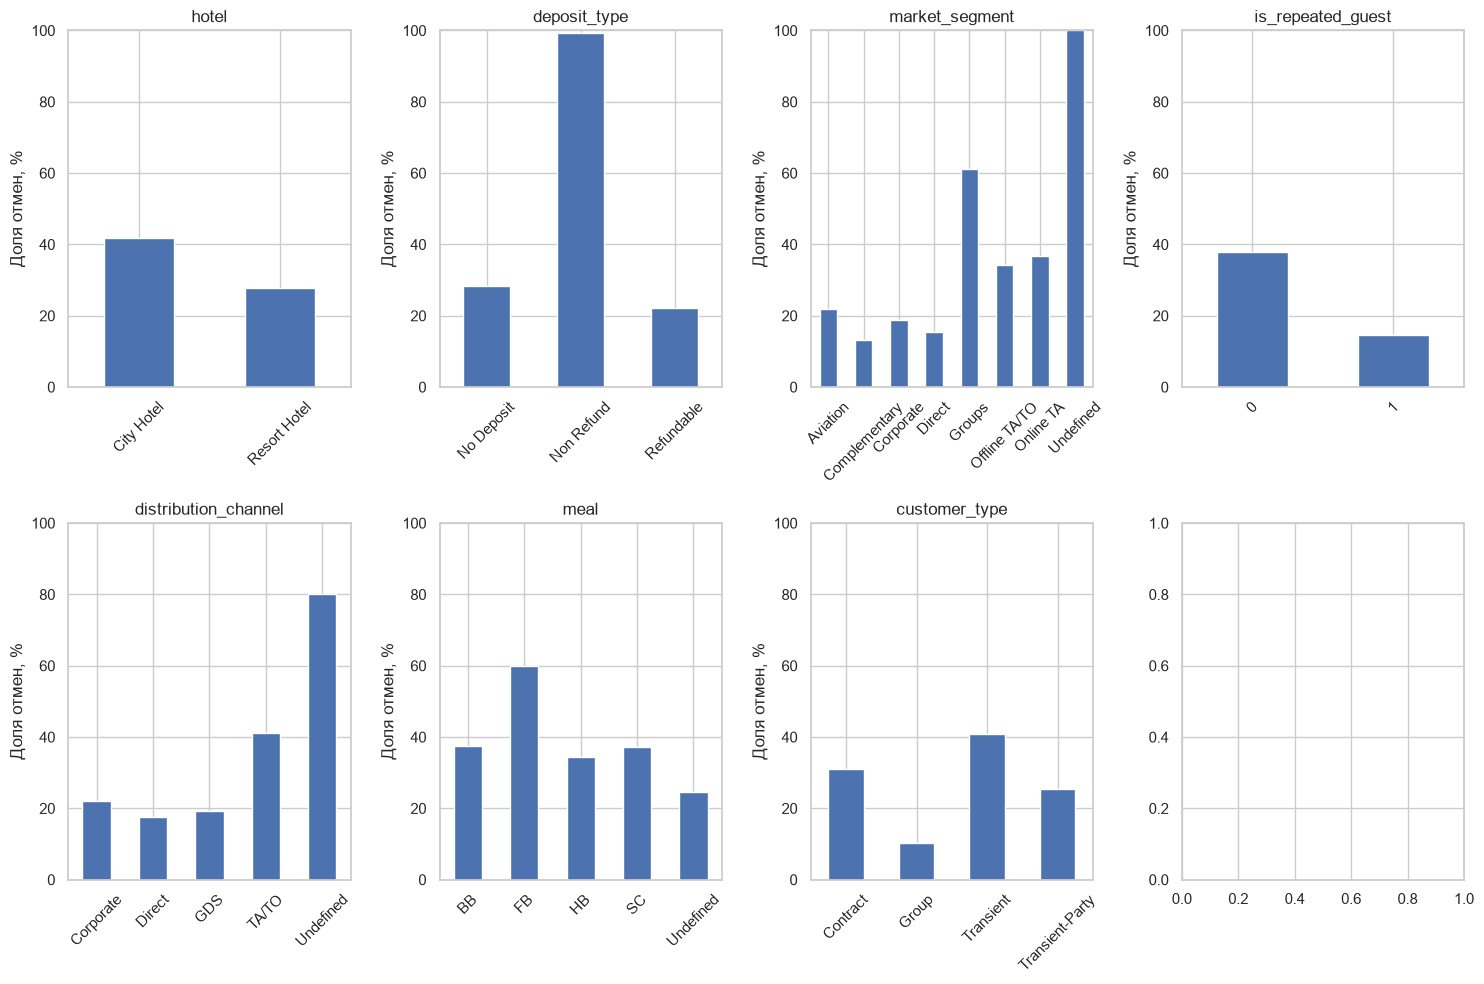

In [87]:
categories = ["hotel", "deposit_type", "market_segment", "is_repeated_guest", "distribution_channel", "meal", "customer_type"]
fig, axes = plt.subplots(2, 4, figsize=(15, 10))

for column, ax in zip(categories, axes.flat):
    stats = df.groupby(column)["is_canceled"].agg(["mean", "count"])
    print("\n", column)
    print(stats.round(3))
    (stats["mean"] * 100).plot(kind="bar", ax=ax, ylim=(0, 100))
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Доля отмен, %")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

В городских отелях доля отмен выше, чем в курортных: около 42% против 28%. Повторные гости отменяют реже (около 15% против 38%). Особенно выделяется `Non Refund`: почти все такие бронирования отмечены как отменённые. Это наблюдаемая связь, а не доказательство причины; перед использованием признака нужно проверить, известен ли тип депозита именно в момент прогноза и нет ли особенностей формирования данных. В редких категориях завышено кол-во отмен, но оценки могут быть несостоятельны.

## Время между бронированием и заездом

                 mean  count
lead_time                   
(-1.0, 7.0]     0.096  19746
(7.0, 30.0]     0.279  18960
(30.0, 90.0]    0.377  29553
(90.0, 180.0]   0.447  26439
(180.0, 365.0]  0.555  21544
(365.0, inf]    0.677   3148


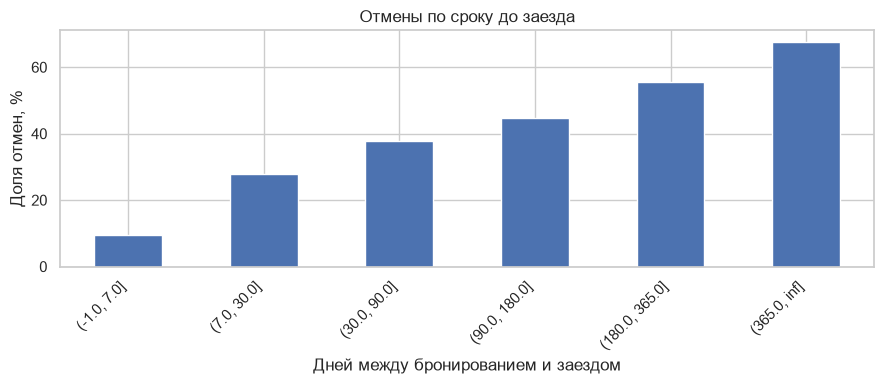

In [88]:
lead_bins = [-1, 7, 30, 90, 180, 365, np.inf]
lead_groups = pd.cut(df["lead_time"], bins=lead_bins)
lead_stats = df.groupby(lead_groups, observed=True)["is_canceled"].agg(["mean", "count"])
print(lead_stats.round(3))

(lead_stats["mean"] * 100).plot(kind="bar", figsize=(9, 4))
plt.xlabel("Дней между бронированием и заездом")
plt.ylabel("Доля отмен, %")
plt.title("Отмены по сроку до заезда")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Чем раньше оформлено бронирование, тем выше наблюдаемая доля отмен: от примерно 10% при сроке до недели до 56% для срока 180–365 дней. Это полезный признак, но группировки могут различаться и по другим характеристикам.

## Стоимость номера (ADR)

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
50%          94.575000
90%         164.000000
95%         193.500000
99%         252.000000
max        5400.000000
Name: adr, dtype: float64
Нулевых значений: 1959
Отрицательных значений: 1


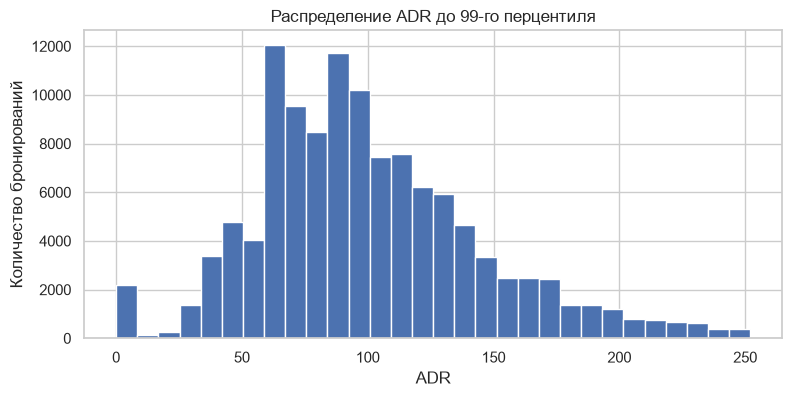

In [89]:
print(df["adr"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
print("Нулевых значений:", (df["adr"] == 0).sum())
print("Отрицательных значений:", (df["adr"] < 0).sum())

upper = df["adr"].quantile(0.99)
ax = df.loc[df["adr"].between(0, upper), "adr"].plot.hist(bins=30, figsize=(9, 4))
ax.set_xlabel("ADR")
ax.set_ylabel("Количество бронирований")
ax.set_title("Распределение ADR до 99-го перцентиля")
plt.show()

                 mean  count
adr                         
(-inf, 0.0]     0.109   1960
(0.0, 50.0]     0.232  10037
(50.0, 100.0]   0.389  55641
(100.0, 150.0]  0.389  35244
(150.0, 200.0]  0.380  11579
(200.0, 250.0]  0.389   3685
(250.0, inf]    0.370   1244


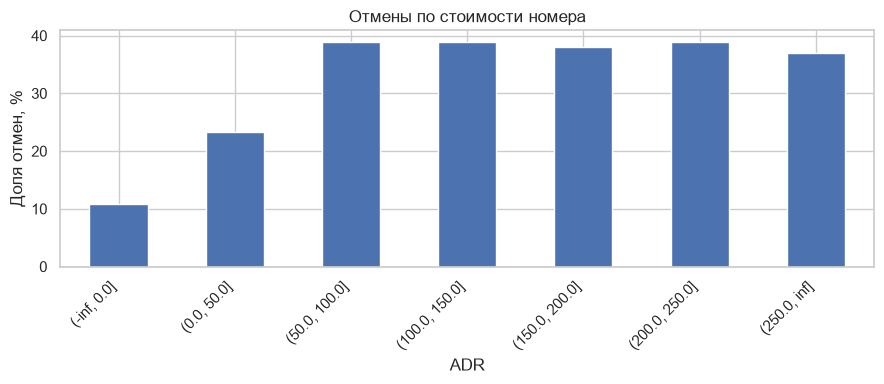

In [90]:
# Нулевые значения оставляем в первой корзине, большие цены — в последней
adr_bins = [-np.inf, 0, 50, 100, 150, 200, 250, np.inf]
adr_groups = pd.cut(df["adr"], bins=adr_bins)
adr_stats = df.groupby(adr_groups, observed=True)["is_canceled"].agg(["mean", "count"])
print(adr_stats.round(3))

(adr_stats["mean"] * 100).plot(kind="bar", figsize=(9, 4))
plt.xlabel("ADR")
plt.ylabel("Доля отмен, %")
plt.title("Отмены по стоимости номера")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Распределение цены имеет длинный правый хвост: медиана около 95, а максимум 5400. На гистограмме для читаемости показаны значения до 99-го перцентиля; при расчёте доли отмен верхняя корзина сохраняет и большие значения. Есть нулевые значения и одно отрицательное — их смысл нужно проверить до обработки. Для линейной модели может пригодиться ограничение выбросов, выбранное только по обучающей выборке.

## Сезонность

                     mean  count
arrival_date_month              
January             0.305   5929
February            0.334   8068
March               0.322   9794
April               0.408  11089
May                 0.397  11791
June                0.415  10939
July                0.375  12661
August              0.378  13877
September           0.392  10508
October             0.380  11160
November            0.312   6794
December            0.350   6780


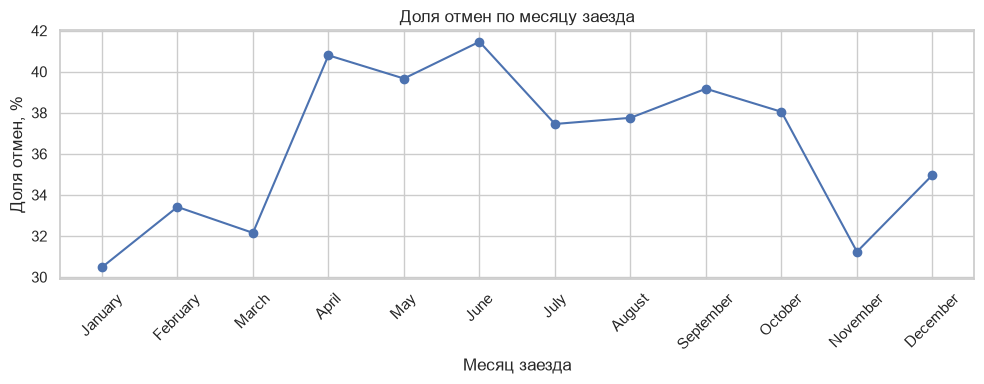

In [91]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
monthly = df.groupby("arrival_date_month")["is_canceled"].agg(["mean", "count"]).reindex(months)
print(monthly.round(3))

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly["mean"] * 100, marker="o")
plt.xlabel("Месяц заезда")
plt.ylabel("Доля отмен, %")
plt.title("Доля отмен по месяцу заезда")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Доля отмен меняется по месяцам, однако это не обязательно эффект сезона: данные охватывают неполные годы, а состав отелей и каналов продаж может меняться со временем. Перед выводами о сезонности стоит отдельно сравнить месяцы внутри каждого года.

## Состав категориальных признаков

Покажем долю каждой категории среди всех бронирований. Это распределение самих признаков, а не доля отмен внутри категории. Пропуски сохраняем отдельным сектором. Названия и количества вынесены в легенды, чтобы подписи редких категорий не накладывались.

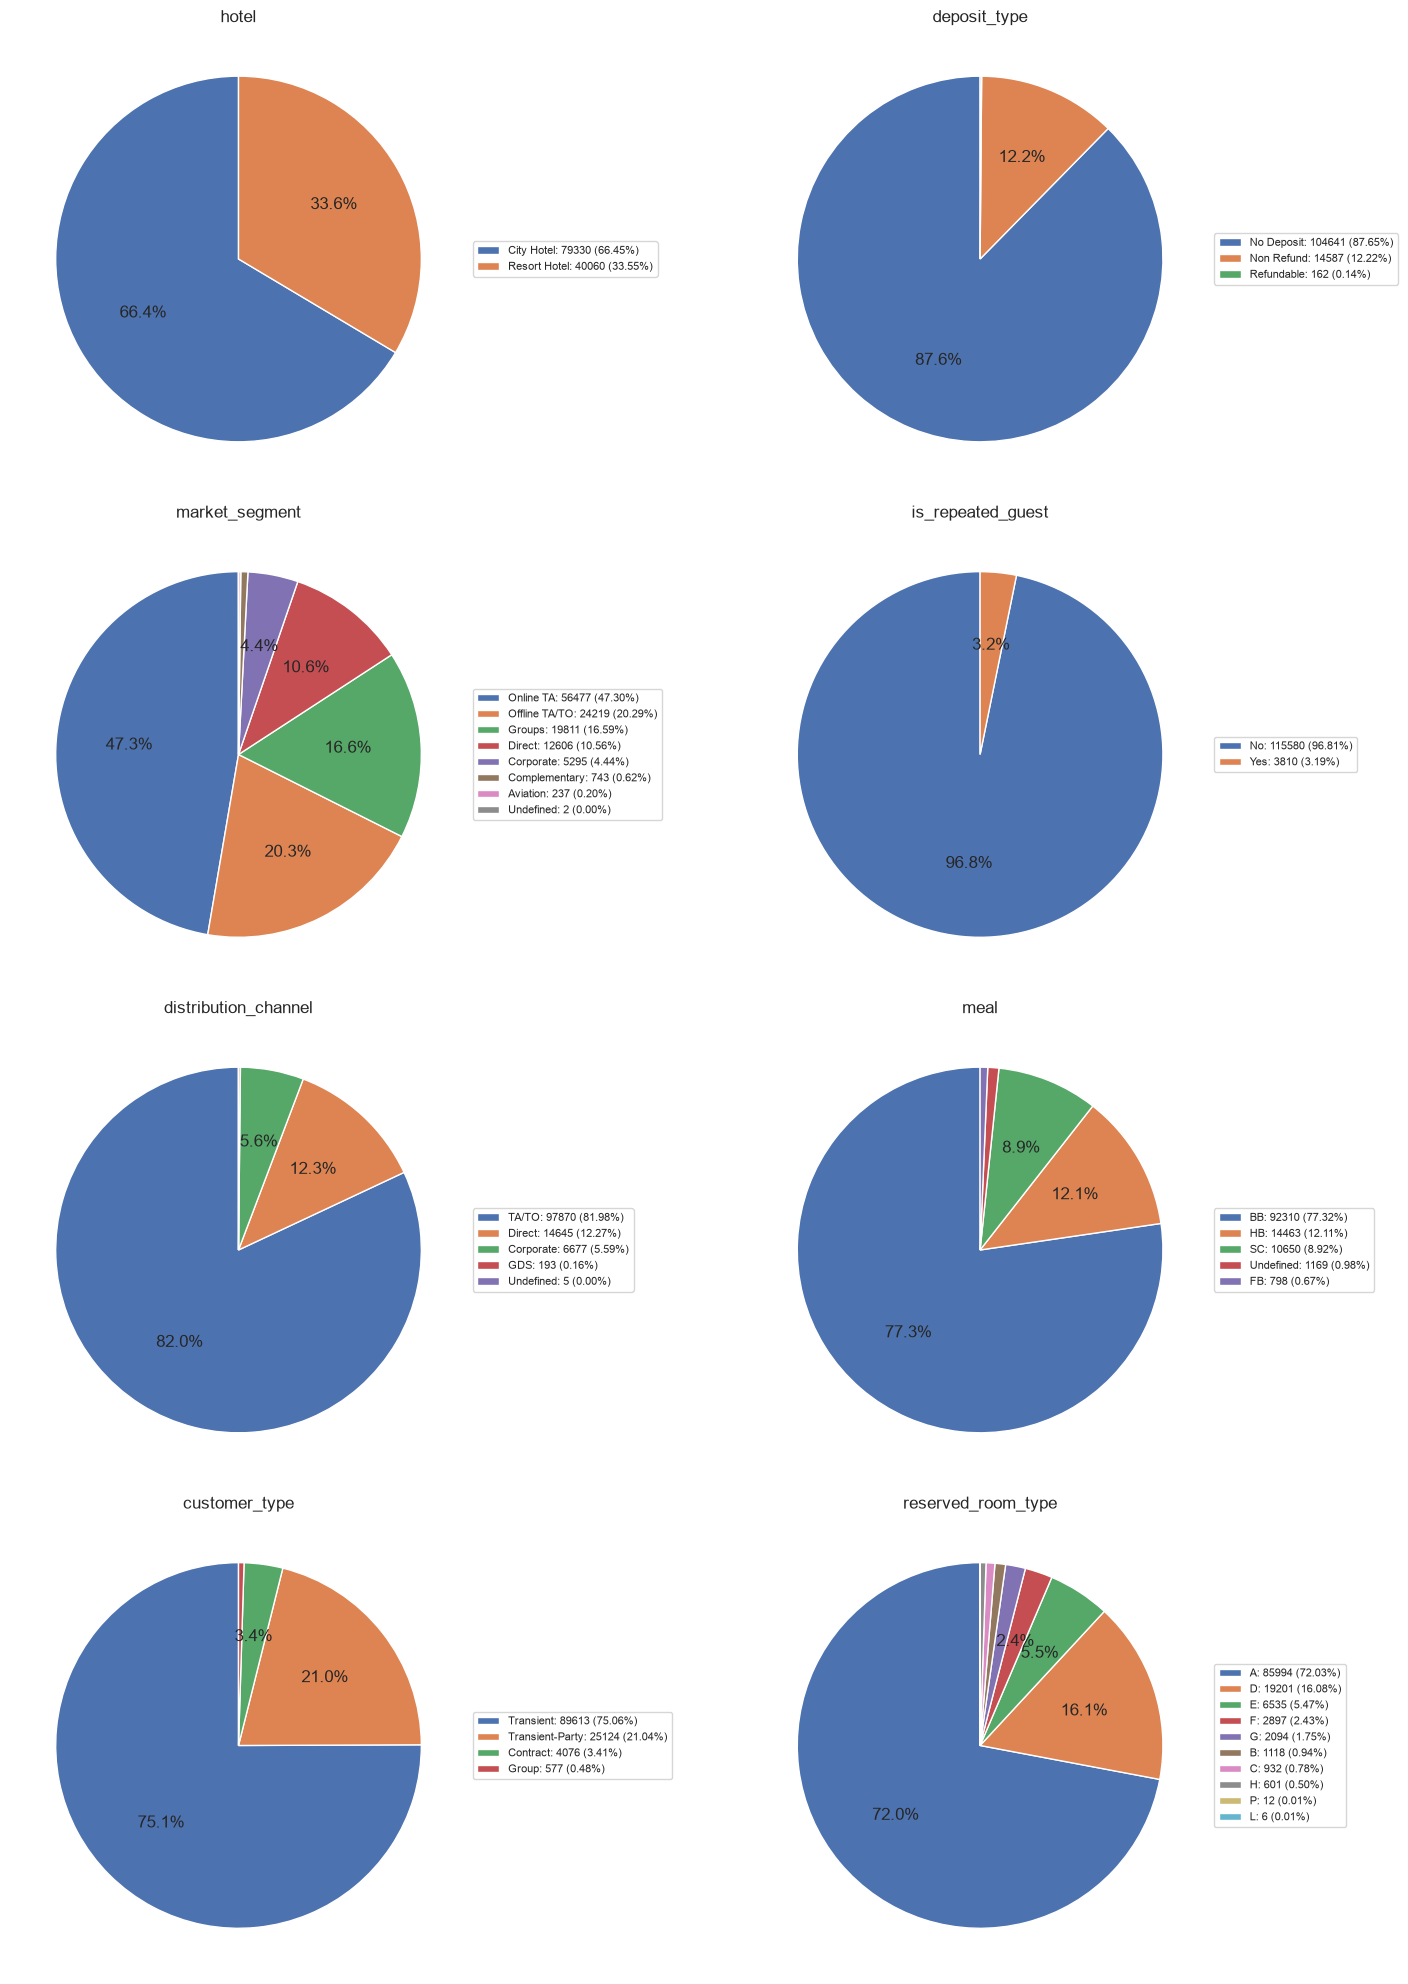

In [92]:
pie_columns = ["hotel", "deposit_type", "market_segment", "is_repeated_guest",
               "distribution_channel", "meal", "customer_type", "reserved_room_type"]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for column, ax in zip(pie_columns, axes.flat):
    counts = df[column].astype("string").fillna("Пропуск").value_counts()
    if column == "is_repeated_guest":
        counts = counts.rename(index={"0": "No", "1": "Yes"})
    wedges, _, _ = ax.pie(
        counts,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 2 else "",
        startangle=90
    )
    labels = [f"{name}: {count} ({count / counts.sum():.2%})"
              for name, count in counts.items()]
    ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
    ax.set_title(column)

plt.tight_layout()
plt.show()

## Распределения численных признаков по отмене

Сравним срок до заезда, ADR и общую длительность проживания. Гистограммы нормированы отдельно внутри каждого класса: большая группа не должна выглядеть выше только из-за своего размера. Границы интервалов одинаковы для обоих классов.

Для гистограмм показываем неотрицательные значения до 99-го перцентиля каждого признака; доли исключённых наблюдений по классам печатаются ниже. Boxplot строится по всем доступным значениям: крайние точки скрыты только на рисунке (`showfliers=False`), но участвуют в расчёте квартилей.

lead_time — исключено из гистограммы, % по классу:
cancel_label
Не отменено    0.39
Отменено       2.00
Name: lead_time, dtype: float64
adr — исключено из гистограммы, % по классу:
cancel_label
Не отменено    0.99
Отменено       0.96
Name: adr, dtype: float64
total_nights — исключено из гистограммы, % по классу:
cancel_label
Не отменено    0.26
Отменено       0.55
Name: total_nights, dtype: float64


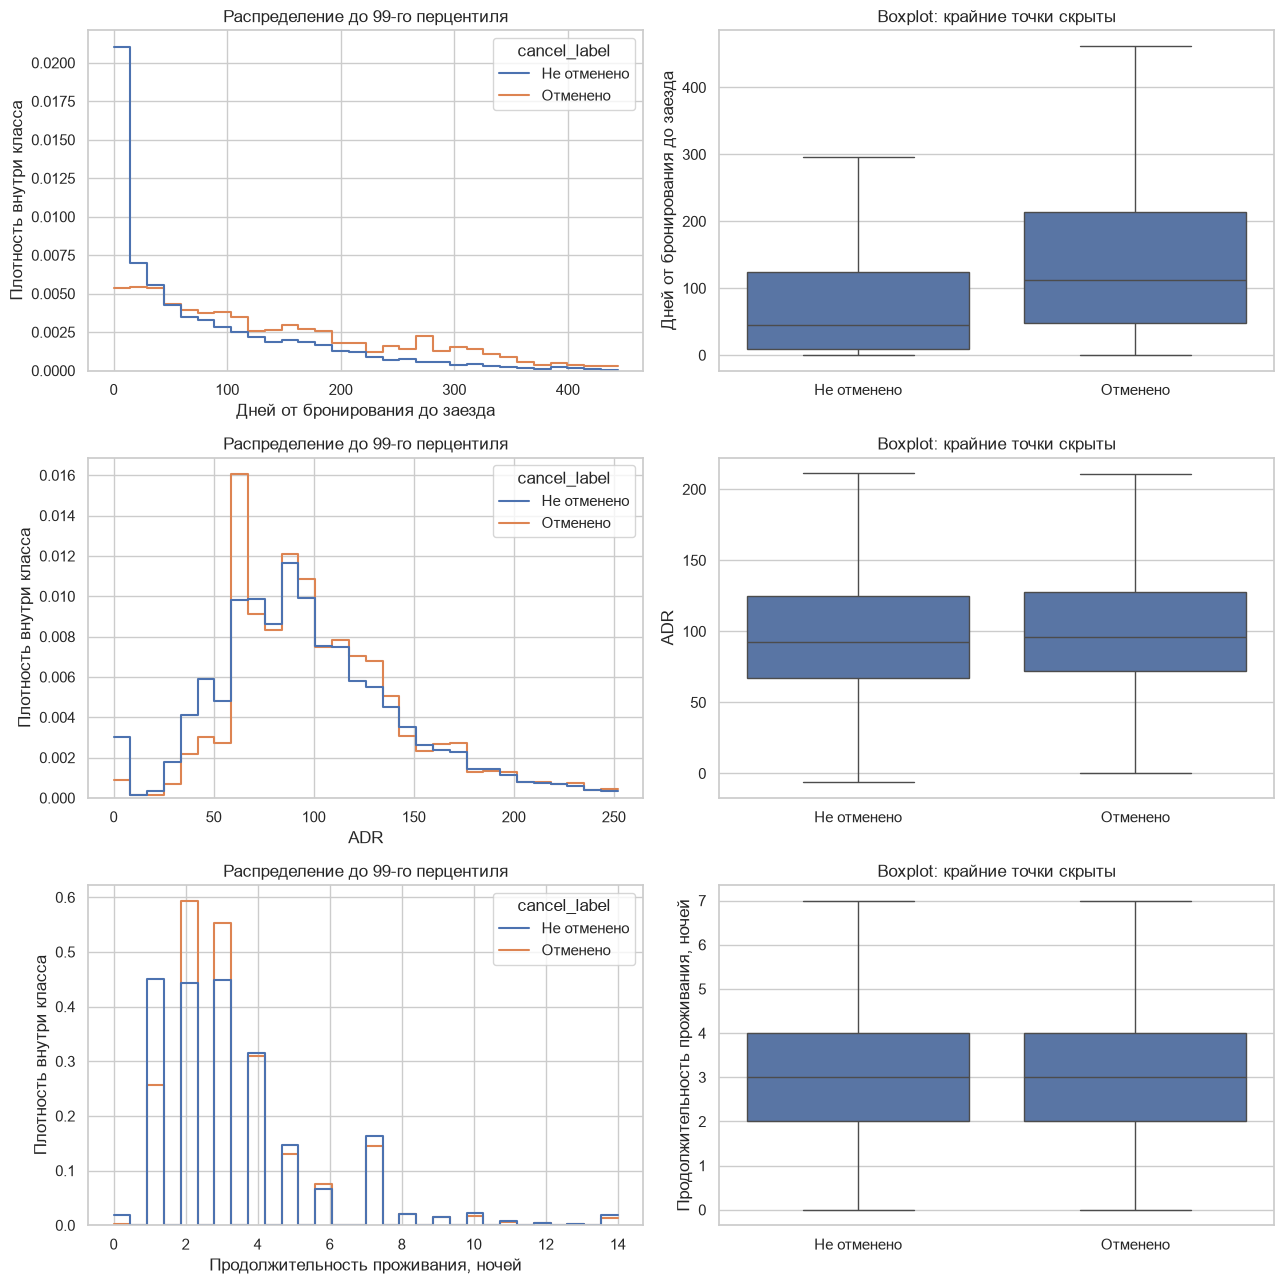

lead_time                   adr                total_nights  \
                 count median    mean  count median    mean        count   
cancel_label                                                               
Не отменено      75166   45.0   79.98  75166   92.5   99.99        75166   
Отменено         44224  113.0  144.85  44224   96.2  104.96        44224   

                           
             median  mean  
cancel_label               
Не отменено     3.0  3.39  
Отменено        3.0  3.49

In [93]:
plot_data = df.assign(
    total_nights=df["stays_in_week_nights"] + df["stays_in_weekend_nights"],
    cancel_label=df["is_canceled"].map({0: "Не отменено", 1: "Отменено"})
)
numeric_plots = {
    "lead_time": "Дней от бронирования до заезда",
    "adr": "ADR",
    "total_nights": "Продолжительность проживания, ночей"
}
order = ["Не отменено", "Отменено"]
fig, axes = plt.subplots(3, 2, figsize=(13, 13))

for row, (column, label) in enumerate(numeric_plots.items()):
    upper = plot_data[column].quantile(0.99)
    mask = plot_data[column].between(0, upper)
    print(column, "— исключено из гистограммы, % по классу:")
    print((~mask).groupby(plot_data["cancel_label"]).mean().mul(100).round(2))
    sns.histplot(
        data=plot_data.loc[mask], x=column, hue="cancel_label",
        hue_order=order, bins=30, stat="density", common_norm=False,
        element="step", fill=False, ax=axes[row, 0]
    )
    axes[row, 0].set_xlabel(label)
    axes[row, 0].set_ylabel("Плотность внутри класса")
    axes[row, 0].set_title("Распределение до 99-го перцентиля")
    sns.boxplot(
        data=plot_data, x="cancel_label", y=column, order=order,
        showfliers=False, ax=axes[row, 1]
    )
    axes[row, 1].set_xlabel("")
    axes[row, 1].set_ylabel(label)
    axes[row, 1].set_title("Boxplot: крайние точки скрыты")

plt.tight_layout()
plt.show()
plot_data.groupby("cancel_label")[list(numeric_plots)].agg(["count", "median", "mean"]).round(2)

## Таблица сопряжённости категорий

Сравним состав каналов продаж в двух типах отелей. Таблица содержит количество бронирований, а тепловая карта — проценты внутри каждого типа отеля (каждая строка суммируется до 100%). Это связь двух признаков, а не таблица долей отмен.

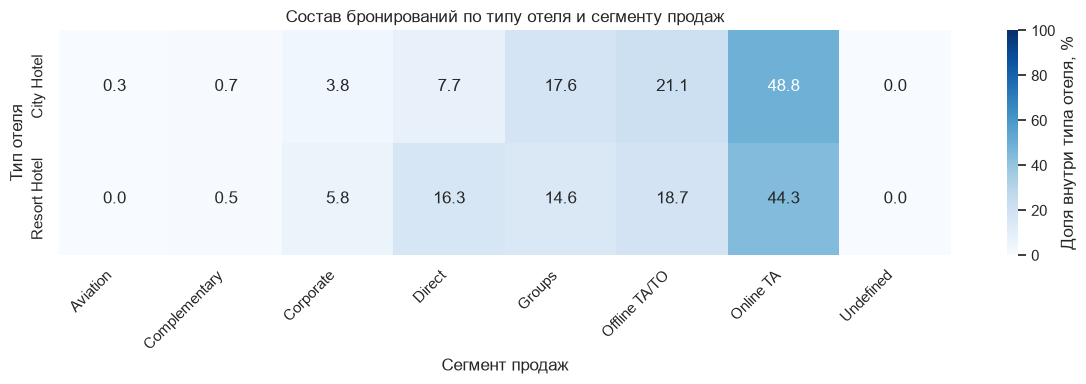

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
hotel,,,,,,,,
City Hotel,237,542,2986,6093,13975,16747,38748,2
Resort Hotel,0,201,2309,6513,5836,7472,17729,0


In [94]:
category_table = pd.crosstab(df["hotel"], df["market_segment"])
category_percent = category_table.div(category_table.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 4))
sns.heatmap(category_percent, annot=True, fmt=".1f", cmap="Blues",
            vmin=0, vmax=100, cbar_kws={"label": "Доля внутри типа отеля, %"})
plt.xlabel("Сегмент продаж")
plt.ylabel("Тип отеля")
plt.title("Состав бронирований по типу отеля и сегменту продаж")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
category_table

### Все пары рассмотренных категориальных признаков

Для восьми признаков получаются 28 уникальных пар. Для каждой пары приводим абсолютные количества и проценты по строкам (до округления каждая строка даёт 100%). Пропуски учитываются отдельно. Эти таблицы описывают совместный состав выборки, а не причинные связи. Редкие категории нужно интерпретировать с учётом количества наблюдений.

In [95]:
from itertools import combinations
from IPython.display import display

category_columns = [
    "hotel", "deposit_type", "market_segment", "is_repeated_guest",
    "distribution_channel", "meal", "customer_type", "reserved_room_type"
]

# Сохраняем пропуски как отдельную категорию
category_data = df[category_columns].astype("string").fillna("Пропуск")
category_data["is_repeated_guest"] = category_data["is_repeated_guest"].replace(
    {"0": "No", "1": "Yes"}
)

crosstabs = {}
for row_column, column_column in combinations(category_columns, 2):
    counts = pd.crosstab(category_data[row_column], category_data[column_column])
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100)
    crosstabs[(row_column, column_column)] = counts

    print(f"{row_column} × {column_column}")
    print("Количество бронирований:")
    display(counts)
    print("Проценты внутри категории по строке:")
    display(percentages.round(1))


hotel × deposit_type
Количество бронирований:


deposit_type,No Deposit,Non Refund,Refundable
hotel,,,
City Hotel,66442,12868,20
Resort Hotel,38199,1719,142


Проценты внутри категории по строке:


deposit_type,No Deposit,Non Refund,Refundable
hotel,,,
City Hotel,83.8,16.2,0.0
Resort Hotel,95.4,4.3,0.4


hotel × market_segment
Количество бронирований:


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
hotel,,,,,,,,
City Hotel,237,542,2986,6093,13975,16747,38748,2
Resort Hotel,0,201,2309,6513,5836,7472,17729,0


... (102 outputs left out)

customer_type × reserved_room_type
Количество бронирований:


reserved_room_type,A,B,C,D,E,F,G,H,L,P
customer_type,,,,,,,,,,
Contract,2867,75,10,843,177,102,1,1,0,0
Group,365,6,5,143,33,10,12,2,0,1
Transient,60948,637,828,16420,5569,2663,1957,574,6,11
Transient-Party,21814,400,89,1795,756,122,124,24,0,0


Проценты внутри категории по строке:


reserved_room_type,A,B,C,D,E,F,G,H,L,P
customer_type,,,,,,,,,,
Contract,70.3,1.8,0.2,20.7,4.3,2.5,0.0,0.0,0.0,0.0
Group,63.3,1.0,0.9,24.8,5.7,1.7,2.1,0.3,0.0,0.2
Transient,68.0,0.7,0.9,18.3,6.2,3.0,2.2,0.6,0.0,0.0
Transient-Party,86.8,1.6,0.4,7.1,3.0,0.5,0.5,0.1,0.0,0.0


## Корреляции численных признаков

Пирсон показывает линейную связь, Спирмен — монотонную связь рангов. Выбираем численные признаки по смыслу: коды агентов и компаний не являются измерениями, а итоговый статус бронирования содержит утечку. Целевую переменную добавим для описательного сравнения.

Корреляции считаются по доступным парам значений. Низкий коэффициент не исключает нелинейную связь, а высокий не доказывает причинность. Доступность признаков на момент оформления всё равно нужно проверить отдельно.

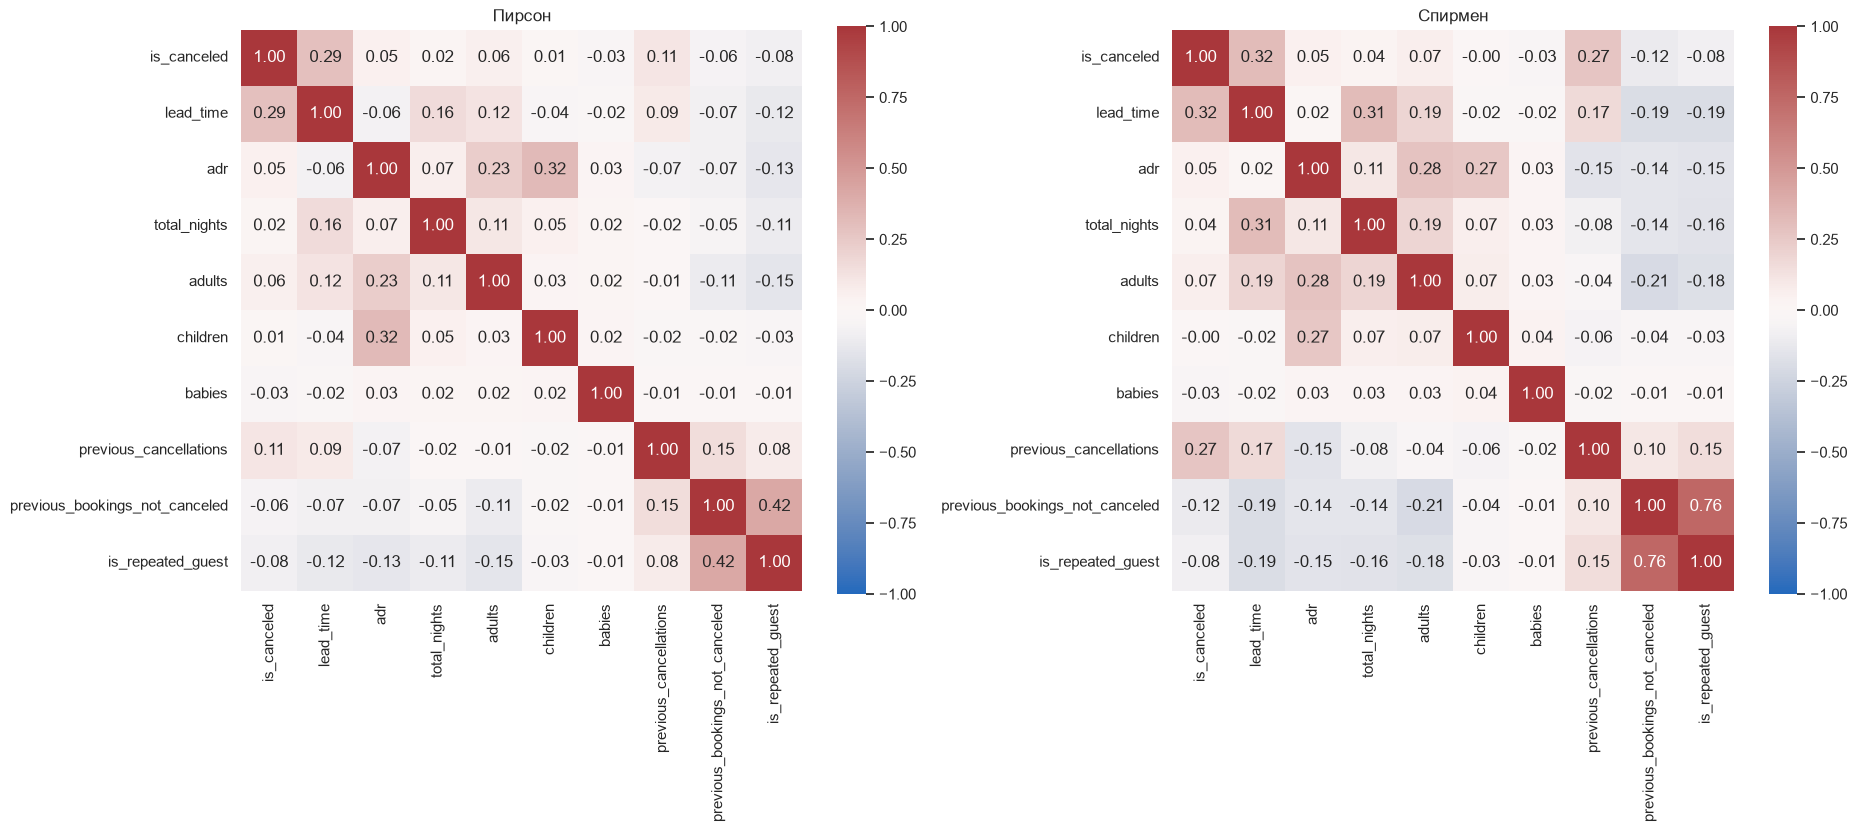

In [96]:
corr_columns = ["is_canceled", "lead_time", "adr", "total_nights",
                "adults", "children", "babies", "previous_cancellations",
                "previous_bookings_not_canceled", "is_repeated_guest"]
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for method, ax in zip(["pearson", "spearman"], axes):
    corr = plot_data[corr_columns].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title("Пирсон" if method == "pearson" else "Спирмен")
plt.tight_layout()
plt.show()

## Проверка качества и смысловых типов

Коды agent/company — категории, а календарные части — временные признаки. Ниже фиксируем роли всех полей и проверяем диапазоны и согласованность. Подозрительное значение не обязательно ошибочно: нулевая длительность или отсутствие взрослых требуют проверки правил учёта.

In [97]:
from IPython.display import display

roles = pd.DataFrame({"тип pandas": df.dtypes.astype(str), "роль": "численный"})
for column in df.select_dtypes(include=["object", "string"]).columns:
    roles.loc[column, "роль"] = "категориальный"
roles.loc[["agent", "company"], "роль"] = "категориальный идентификатор"
roles.loc[["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"], "роль"] = "календарный"
roles.loc["is_canceled", "роль"] = "целевая переменная"
roles.loc[["reservation_status", "reservation_status_date"], "роль"] = "итог: исключить из модели"
display(roles)

eda = df.copy()
eda["total_nights"] = eda["stays_in_week_nights"] + eda["stays_in_weekend_nights"]
month_names = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
eda["arrival_date"] = pd.to_datetime(pd.DataFrame({
    "year": eda["arrival_date_year"],
    "month": eda["arrival_date_month"].map(dict(zip(month_names, range(1, 13)))),
    "day": eda["arrival_date_day_of_month"]
}), errors="coerce")
checks = {
    "отрицательный ADR": eda["adr"].lt(0),
    "нулевой ADR": eda["adr"].eq(0),
    "нулевая длительность": eda["total_nights"].eq(0),
    "нет гостей (все количества известны)": eda[["adults", "children", "babies"]].sum(axis=1, min_count=3).eq(0),
    "некорректная дата заезда": eda["arrival_date"].isna(),
    "неделя вне 1–53": ~eda["arrival_date_week_number"].between(1, 53),
    "таргет вне 0/1": ~eda["is_canceled"].isin([0, 1])
}
for column in ["adults", "children", "babies", "stays_in_week_nights", "stays_in_weekend_nights", "lead_time", "previous_cancellations", "previous_bookings_not_canceled"]:
    checks[f"отрицательные {column}"] = eda[column].lt(0)
print(pd.Series({name: int(mask.sum()) for name, mask in checks.items()}))
print("Бесконечности:", np.isinf(df.select_dtypes(include="number")).sum().sum())
display(eda.loc[checks["нет гостей (все количества известны)"] | checks["отрицательный ADR"],
                ["hotel", "adults", "children", "babies", "adr", "total_nights", "is_canceled"]].head(10))

,тип pandas,роль
hotel,str,категориальный
is_canceled,int64,целевая переменная
lead_time,int64,численный
arrival_date_year,int64,календарный
arrival_date_month,str,календарный
arrival_date_week_number,int64,календарный
arrival_date_day_of_month,int64,календарный
stays_in_weekend_nights,int64,численный
stays_in_week_nights,int64,численный
adults,int64,численный


отрицательный ADR                                  1
нулевой ADR                                     1959
нулевая длительность                             715
нет гостей (все количества известны)             180
некорректная дата заезда                           0
неделя вне 1–53                                    0
таргет вне 0/1                                     0
отрицательные adults                               0
отрицательные children                             0
отрицательные babies                               0
отрицательные stays_in_week_nights                 0
отрицательные stays_in_weekend_nights              0
отрицательные lead_time                            0
отрицательные previous_cancellations               0
отрицательные previous_bookings_not_canceled       0
dtype: int64
Бесконечности: 0


,hotel,adults,children,babies,adr,total_nights,is_canceled
2224,Resort Hotel,0,0.0,0,0.00,3,0
2409,Resort Hotel,0,0.0,0,0.00,0,0
3181,Resort Hotel,0,0.0,0,0.00,3,0
3684,Resort Hotel,0,0.0,0,0.00,5,0
3708,Resort Hotel,0,0.0,0,0.00,6,0
4127,Resort Hotel,0,0.0,0,0.00,0,1
9376,Resort Hotel,0,0.0,0,0.00,0,1
14969,Resort Hotel,2,0.0,0,-6.38,10,0
31765,Resort Hotel,0,0.0,0,28.00,10,0
32029,Resort Hotel,0,0.0,0,0.00,1,0


Найдено 180 строк без гостей, 715 с нулевой длительностью и одна с отрицательным ADR. Некорректных дат, бесконечностей и отрицательных проверенных счётчиков нет. Подозрительные строки сохраняем до выяснения их смысла.

## Текстовые категории и повторы

Сравниваем число категорий до и после удаления пробелов и нормализации регистра. Полные совпадения строк рассматриваем как кандидаты на дубли: без ID бронирования доказать повторную запись нельзя. Не вводим искусственный ключ из отеля и даты — разные гости могут бронировать одинаковые номера.

In [98]:
text_rows = []
for column in df.select_dtypes(include=["object", "string"]).columns:
    values = df[column].dropna().astype("string")
    text_rows.append([column, values.ne(values.str.strip()).sum(), values.nunique(), values.str.strip().str.lower().nunique()])
display(pd.DataFrame(text_rows, columns=["поле", "пробелы по краям", "категорий", "после нормализации"]))
repeat_mask = df.duplicated(keep=False)
print("Строки во всех группах полных совпадений:", repeat_mask.sum())
print("Лишние копии при сохранении одной строки:", df.duplicated().sum())
display(df.assign(repeated=repeat_mask).groupby("hotel")["repeated"].agg(["size", "sum", "mean"]))
display(df.loc[repeat_mask].head(5))

,поле,пробелы по краям,категорий,после нормализации
0,hotel,0,2,2
1,arrival_date_month,0,12,12
2,meal,0,5,5
3,country,0,177,177
4,market_segment,0,8,8
5,distribution_channel,0,5,5
6,reserved_room_type,0,10,10
7,assigned_room_type,0,12,12
8,deposit_type,0,3,3
9,customer_type,0,4,4


Строки во всех группах полных совпадений: 40165
Лишние копии при сохранении одной строки: 31994


,size,sum,mean
hotel,,,
City Hotel,79330,31748,0.400202
Resort Hotel,40060,8417,0.210110


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07


Нормализация пробелов и регистра не уменьшает число категорий. В группы полных совпадений входит 40 165 строк; копий сверх одной записи на группу — 31 994. Доля строк в таких группах: около 40% в City Hotel и 21% в Resort Hotel.

## Структура пропусков

Проверим сочетания пропусков agent/company, их распространённость по группам и долю отмен при наличии и отсутствии значения. Совпадение пропусков или различия групп не доказывают механизм их возникновения.

company отсутствует,False,True
agent отсутствует,,
False,217,102833
True,6580,9760


agent


,size,mean
пропуск,,
False,103050,0.390044
True,16340,0.246634


company


,size,mean
пропуск,,
False,6797,0.175224
True,112593,0.382200


country


,size,mean
пропуск,,
False,118902,0.371373
True,488,0.137295


children


,size,mean
пропуск,,
False,119386,0.370395
True,4,1.000000


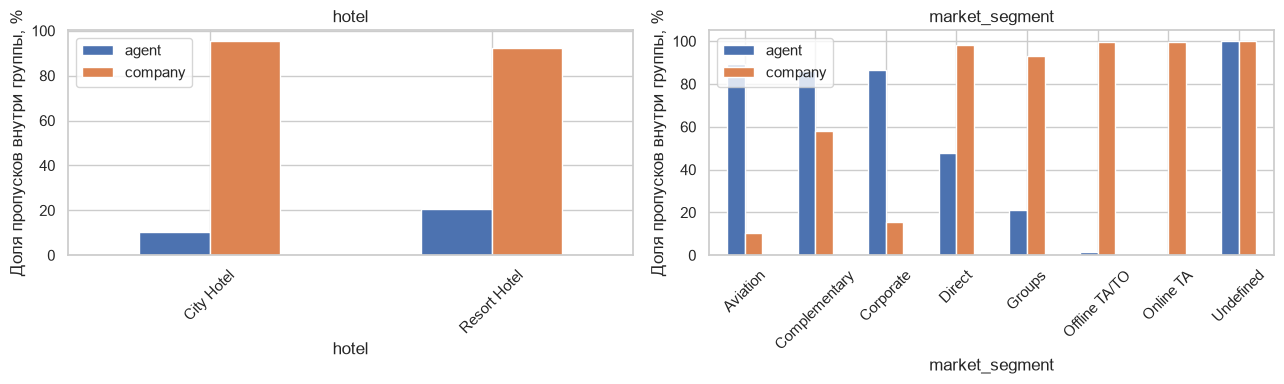

In [99]:
display(pd.crosstab(df["agent"].isna().rename("agent отсутствует"), df["company"].isna().rename("company отсутствует")))
for column in ["agent", "company", "country", "children"]:
    print(column)
    display(df.groupby(df[column].isna().rename("пропуск"))["is_canceled"].agg(["size", "mean"]))
missing_flags = df[["agent", "company"]].isna().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for category, ax in zip(["hotel", "market_segment"], axes):
    missing_flags.groupby(df[category]).mean().plot.bar(ax=ax)
    ax.set_ylabel("Доля пропусков внутри группы, %")
    ax.set_title(category)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

При отсутствии agent доля отмен — 24,7%, при известном агенте — 39,0%. При известной company — 17,5%, при отсутствии — 38,2%. Пропуски связаны с составом бронирований; это не повод безусловно удалять строки.

## Состав выборки и время

Покажем страны и покрытие по месяцам и годам. Строка — бронирование, а не уникальный гость. По этим данным нельзя оценить число уникальных гостей. Отсутствующие месяцы оставляем пустыми, а не обозначаем нулём.

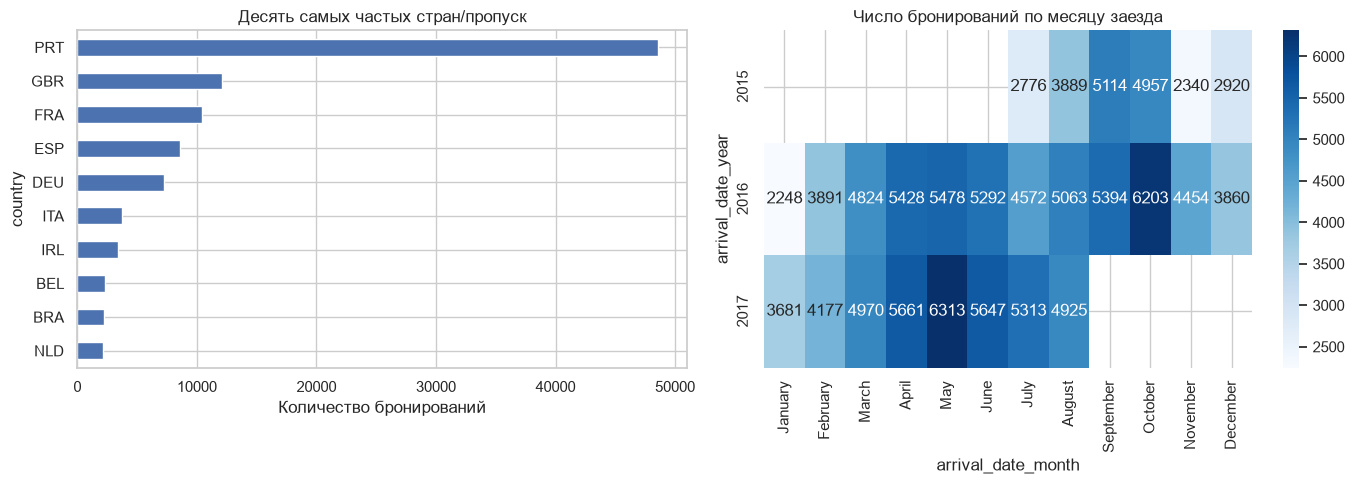

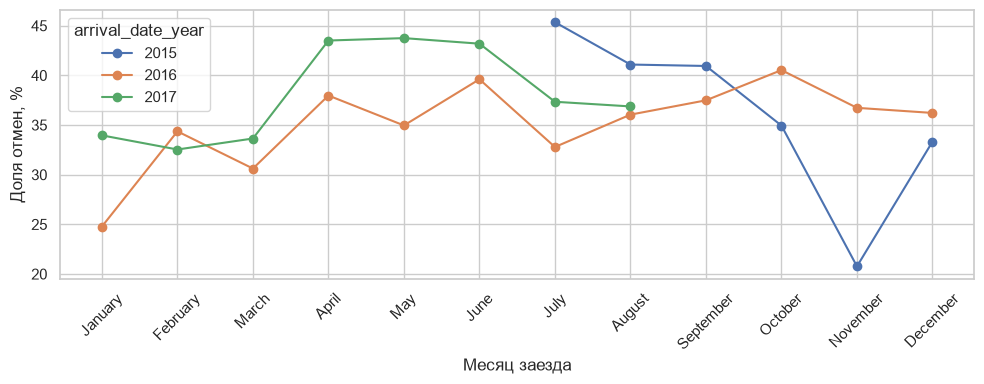

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["country"].fillna("Пропуск").value_counts().head(10).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Десять самых частых стран/пропуск")
axes[0].set_xlabel("Количество бронирований")
coverage = pd.crosstab(df["arrival_date_year"], df["arrival_date_month"]).reindex(columns=month_names)
sns.heatmap(coverage.replace(0, np.nan), annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Число бронирований по месяцу заезда")
plt.tight_layout()
plt.show()
season = df.groupby(["arrival_date_month", "arrival_date_year"])["is_canceled"].mean().unstack().reindex(month_names)
season.mul(100).plot(marker="o", figsize=(10, 4))
plt.ylabel("Доля отмен, %")
plt.xlabel("Месяц заезда")
plt.xticks(range(12), month_names, rotation=45)
plt.tight_layout()
plt.show()

Покрытие неполное: 2015 год начинается с июля, 2017 заканчивается августом. Агрегированный график по месяцам смешивает разные наборы лет.

## ECDF и масштабы распределения

ECDF показывает долю наблюдений класса со значением не больше x и не требует выбора бинов. Для сравнения шкал ADR используются только положительные значения; нули и отрицательные остаются в исходной таблице.

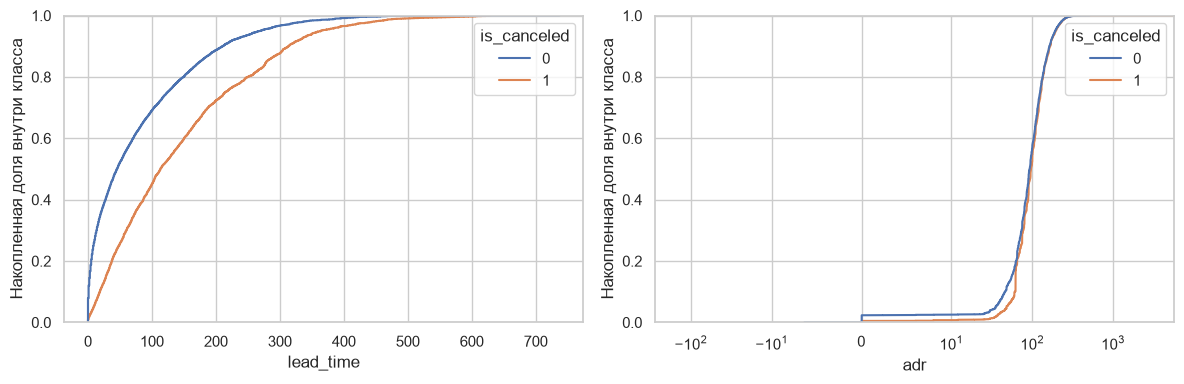

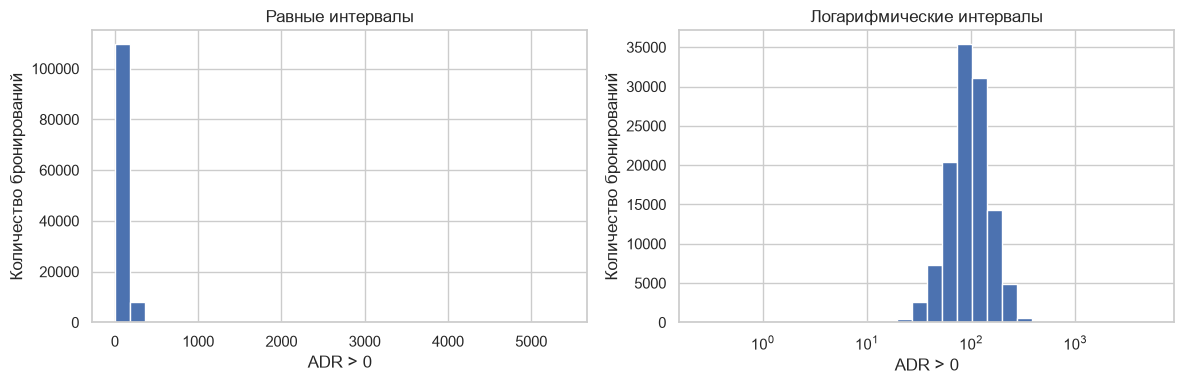

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, ax in zip(["lead_time", "adr"], axes):
    sns.ecdfplot(data=df, x=column, hue="is_canceled", ax=ax)
    ax.set_ylabel("Накопленная доля внутри класса")
axes[1].set_xscale("symlog", linthresh=10)
plt.tight_layout()
plt.show()
positive_adr = df.loc[df["adr"] > 0, "adr"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(positive_adr, bins=30)
axes[1].hist(positive_adr, bins=np.geomspace(positive_adr.min(), positive_adr.max(), 31))
axes[1].set_xscale("log")
for ax in axes:
    ax.set_xlabel("ADR > 0")
    ax.set_ylabel("Количество бронирований")
axes[0].set_title("Равные интервалы")
axes[1].set_title("Логарифмические интервалы")
plt.tight_layout()
plt.show()

## Необычные значения и устойчивость выводов

Правило 1,5 IQR выделяет необычные значения, но не доказывает ошибку. Рассмотрим строки с максимальным ADR и частые цены. Сравним корреляции и долю отмен при разных сценариях, не меняя исходные данные.

In [102]:
iqr_rows = []
for column in ["adr", "lead_time", "total_nights"]:
    q1, q3 = eda[column].quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    count = ((eda[column] < lower) | (eda[column] > upper)).sum()
    iqr_rows.append([column, lower, upper, count])
display(pd.DataFrame(iqr_rows, columns=["поле", "нижняя граница", "верхняя граница", "кандидатов"]))
display(eda.nlargest(5, "adr")[["hotel", "adr", "adults", "children", "total_nights", "is_canceled"]])
display(df["adr"].value_counts().head(10).rename("количество"))
scenarios = {"Все": df, "Без верхнего 1% ADR": df[df["adr"] <= df["adr"].quantile(0.99)], "Без отрицательного ADR": df[df["adr"] >= 0], "Без полных дублей (сценарий)": df.drop_duplicates()}
rows = []
for name, data in scenarios.items():
    rows.append([name, len(data), data["is_canceled"].mean() * 100,
                 data["adr"].corr(data["is_canceled"]), data["adr"].corr(data["is_canceled"], method="spearman")])
display(pd.DataFrame(rows, columns=["сценарий", "строк", "отмен, %", "ADR: Пирсон", "ADR: Спирмен"]).round(3))

,поле,нижняя граница,верхняя граница,кандидатов
0,adr,-15.775,211.065,3793
1,lead_time,-195.000,373.000,3005
2,total_nights,-1.000,7.000,5257


,hotel,adr,adults,children,total_nights,is_canceled
48515,City Hotel,5400.0,2,0.0,1,1
111403,City Hotel,510.0,1,0.0,1,0
15083,Resort Hotel,508.0,2,0.0,1,0
103912,City Hotel,451.5,2,2.0,2,0
13142,Resort Hotel,450.0,2,0.0,14,1


adr
62.0     3754
75.0     2715
90.0     2473
65.0     2418
0.0      1959
80.0     1889
95.0     1661
120.0    1607
100.0    1573
85.0     1538
Name: количество, dtype: int64

,сценарий,строк,"отмен, %",ADR: Пирсон,ADR: Спирмен
0,Все,119390,37.042,0.048,0.051
1,Без верхнего 1% ADR,118222,37.047,0.054,0.052
2,Без отрицательного ADR,119389,37.042,0.048,0.051
3,Без полных дублей (сценарий),87396,27.490,0.128,0.143


Максимальный ADR 5400 сильно отделён от следующего значения 510: запись стоит проверить. Исключение верхнего 1% ADR мало меняет его корреляцию с отменой. Удаление полных дублей меняет долю отмен с 37,0% до 27,5% — это существенное изменение состава выборки. Отрицательный ADR не выходит за границы 1,5 IQR: статистическое правило не заменяет проверку предметного смысла.

## Связи внутри групп и влияние бинов

Проверим зависимость отмен от срока до заезда отдельно по отелям и при разных интервалах. Пустые корзины не заменяем нулевыми долями. Scatterplot использует случайную выборку из 3000 строк для читаемости; это не полное отображение хвостов.

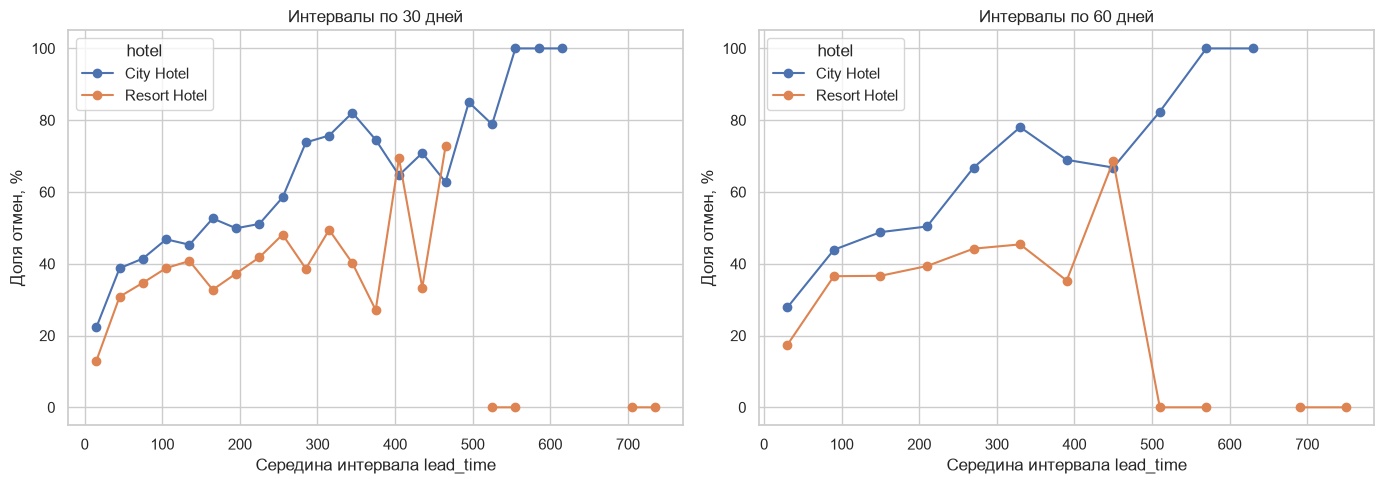

Число наблюдений по корзинам последнего графика:


hotel,City Hotel,Resort Hotel
lead_time,,
"(-0.001, 60.0]",35251,20425
"(60.0, 120.0]",16355,6662
"(120.0, 180.0]",10776,5229
"(180.0, 240.0]",6099,3871
"(240.0, 300.0]",4643,2192
"(300.0, 360.0]",3341,1130
"(360.0, 420.0]",1385,439
"(420.0, 480.0]",955,86
"(480.0, 540.0]",244,1


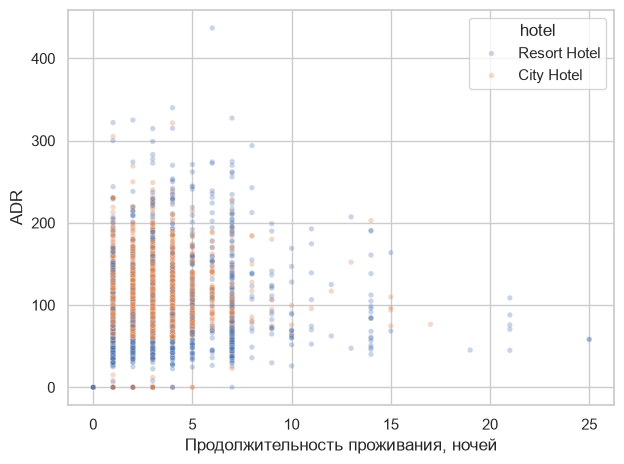

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for width, ax in zip([30, 60], axes):
    groups = pd.cut(df["lead_time"], bins=np.arange(0, df["lead_time"].max() + width, width), include_lowest=True)
    rates = df.groupby([groups, "hotel"], observed=True)["is_canceled"].mean().unstack()
    rates.index = [interval.mid for interval in rates.index]
    rates.mul(100).plot(marker="o", ax=ax)
    ax.set_title(f"Интервалы по {width} дней")
    ax.set_xlabel("Середина интервала lead_time")
    ax.set_ylabel("Доля отмен, %")
plt.tight_layout()
plt.show()
print("Число наблюдений по корзинам последнего графика:")
display(pd.crosstab(groups, df["hotel"]))
sns.scatterplot(data=eda.sample(n=min(3000, len(eda)), random_state=42), x="total_nights", y="adr", hue="hotel", alpha=0.3, s=15)
plt.xlabel("Продолжительность проживания, ночей")
plt.ylabel("ADR")
plt.tight_layout()
plt.show()

## Выводы и дальнейшая работа

- Данные позволяют построить модель отмены, но наблюдаемые зависимости сами по себе не доказывают причинность.
- Для честной оценки нужно зафиксировать момент прогноза и исключить признаки, известные после него. Например, `reservation_status` и `reservation_status_date` раскрывают итог бронирования; `assigned_room_type`, `booking_changes` и `days_in_waiting_list` тоже требуют проверки доступности на момент оформления.
- Для прогноза будущих бронирований желательно разделять данные по времени, а не случайно; преобразования, заполнение пропусков и подбор порога выполнять без использования тестовой выборки.
- Категориальные признаки потребуется закодировать, пропуски и выбросы обработать с учётом их смысла. Проверить качество отдельно для разных отелей и периодов.